In [9]:
import  numpy               as np
import  matplotlib.pyplot   as plt
from    GA                  import *

In [10]:
base = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
state0 = [999, 1, 0]
t_max = 150
n_runs = 100
t_grid = np.linspace(0, t_max, 500)
names = ["S", "I", "R"]

import matplotlib.patheffects as pe

outline = [pe.Stroke(linewidth=4, foreground="white"), pe.Normal()]

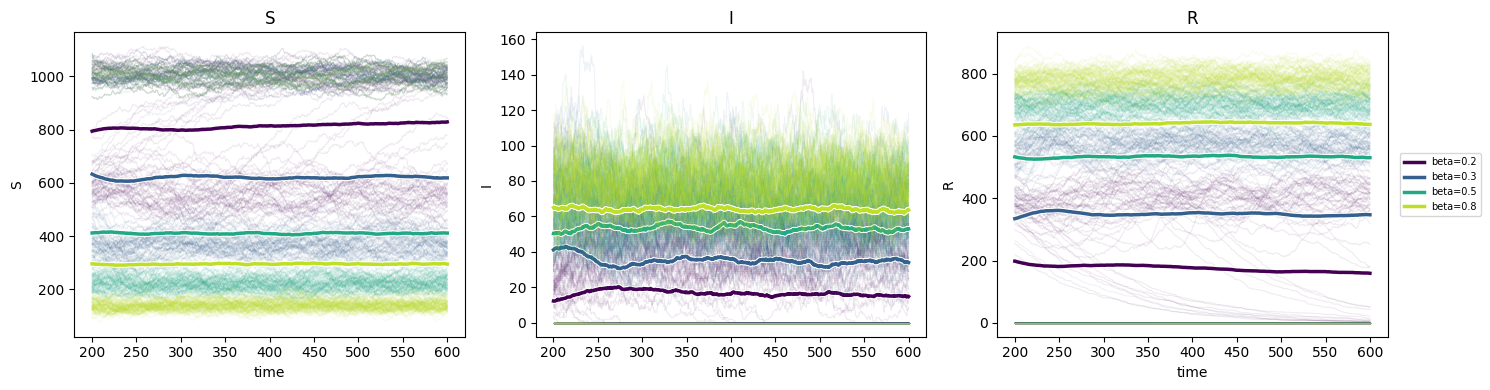

In [5]:
name = "beta"
values = [0.2, 0.3, 0.5, 0.8]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(values)))

t_max_long = 600
t_burn = 200
t_grid_long = np.linspace(0, t_max_long, 1200)
after = t_grid_long >= t_burn
t_plot = t_grid_long[after]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for value, color in zip(values, colors):
    params = {**base, name: value}
    runs = run_ensemble(state0, params, t_max_long, n_runs, t_grid_long)
    runs = runs[:, after, :]

    for i in range(3):
        axes[i].plot(t_plot, runs[:, :, i].T, color=color, alpha=0.08,
                     linewidth=0.8)
        axes[i].plot(t_plot, runs[:, :, i].mean(axis=0), color=color,
                     linewidth=2.5, path_effects=outline,
                     label=f"{name}={value}")

for ax, compartment in zip(axes, names):
    ax.set_xlabel("time")
    ax.set_ylabel(compartment)
    ax.set_title(compartment)

axes[2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

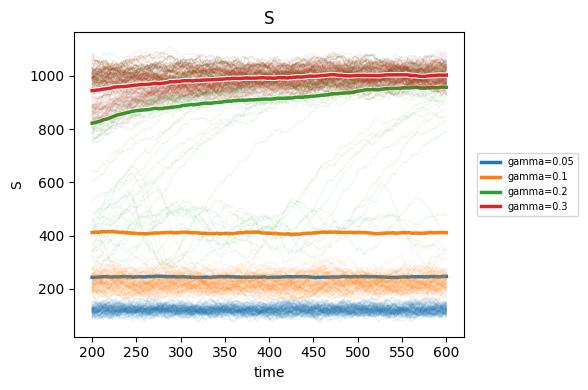

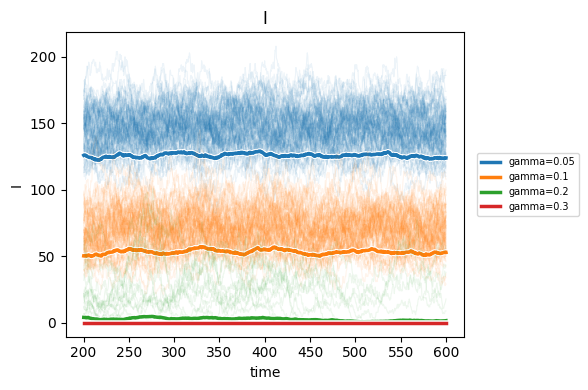

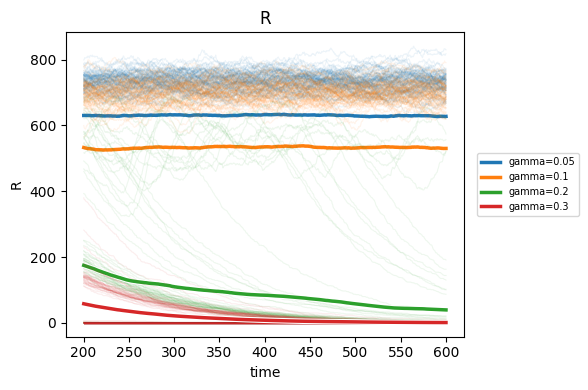

In [11]:
import matplotlib.patheffects as pe

name = "gamma"
values = [0.05, 0.1, 0.2, 0.3]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
outline = [pe.Stroke(linewidth=4, foreground="white"), pe.Normal()]

t_max_long = 600
t_burn = 200
t_grid_long = np.linspace(0, t_max_long, 1200)
after = t_grid_long >= t_burn
t_plot = t_grid_long[after]

all_runs = []
for value in values:
    params = {**base, name: value}
    runs = run_ensemble(state0, params, t_max_long, n_runs, t_grid_long)
    all_runs.append(runs[:, after, :])

for i, compartment in enumerate(names):
    fig, ax = plt.subplots(figsize=(6, 4))

    for value, color, runs in zip(values, colors, all_runs):
        ax.plot(t_plot, runs[:, :, i].T, color=color, alpha=0.08,
                linewidth=0.8)
        ax.plot(t_plot, runs[:, :, i].mean(axis=0), color=color,
                linewidth=2.5, path_effects=outline,
                label=f"{name}={value}")

    ax.set_xlabel("time")
    ax.set_ylabel(compartment)
    ax.set_title(compartment)
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()
    plt.show()

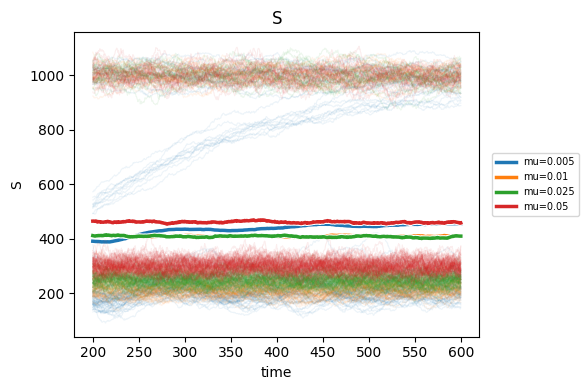

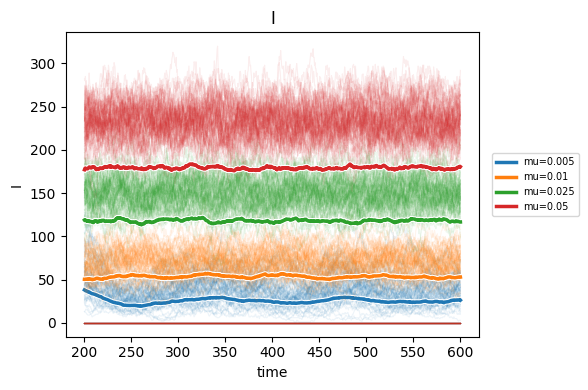

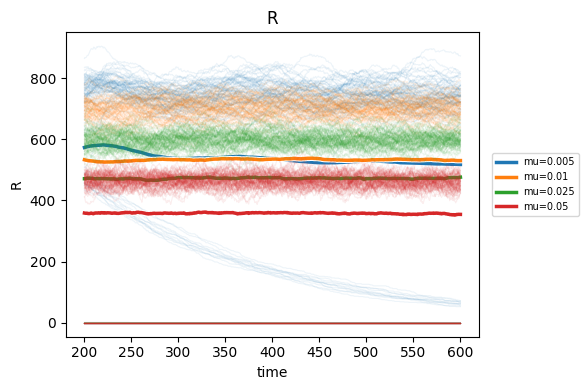

In [12]:
import matplotlib.patheffects as pe

name = "mu"
values = [0.005, 0.01, 0.025, 0.05]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
outline = [pe.Stroke(linewidth=4, foreground="white"), pe.Normal()]

t_max_long = 600
t_burn = 200
t_grid_long = np.linspace(0, t_max_long, 1200)
after = t_grid_long >= t_burn
t_plot = t_grid_long[after]

all_runs = []
for value in values:
    params = {**base, name: value}
    runs = run_ensemble(state0, params, t_max_long, n_runs, t_grid_long)
    all_runs.append(runs[:, after, :])

for i, compartment in enumerate(names):
    fig, ax = plt.subplots(figsize=(6, 4))

    for value, color, runs in zip(values, colors, all_runs):
        ax.plot(t_plot, runs[:, :, i].T, color=color, alpha=0.08,
                linewidth=0.8)
        ax.plot(t_plot, runs[:, :, i].mean(axis=0), color=color,
                linewidth=2.5, path_effects=outline,
                label=f"{name}={value}")

    ax.set_xlabel("time")
    ax.set_ylabel(compartment)
    ax.set_title(compartment)
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()
    plt.show()

In [13]:
def power_spectrum(I_runs, dt):

    x = I_runs - I_runs.mean(axis=1, keepdims=True)
    x = x * np.hanning(x.shape[1])
    psd = (np.abs(np.fft.rfft(x, axis=1)) ** 2).mean(axis=0)
    freqs = np.fft.rfftfreq(x.shape[1], d=dt)

    return freqs, psd * dt / x.shape[1]


def natural_frequency(params):

    beta, gamma, mu = params["beta"], params["gamma"], params["mu"]
    R0 = beta / (gamma + mu)
    a = mu * R0 / 2
    omega = np.sqrt(beta * mu * (R0 - 1) / R0 - a ** 2)

    return omega / (2 * np.pi)

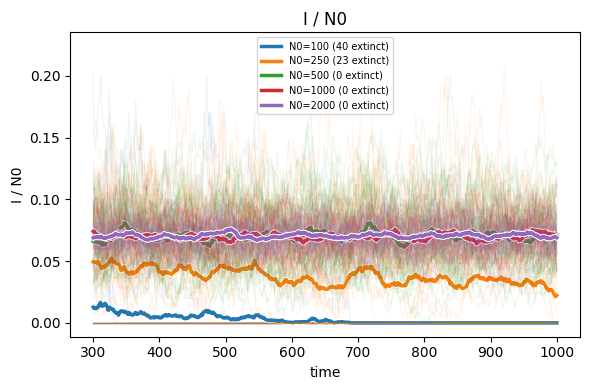

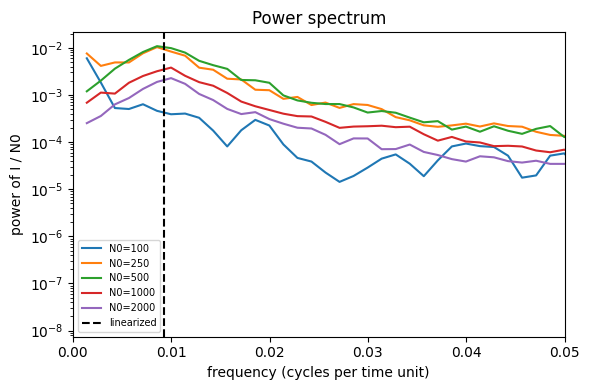

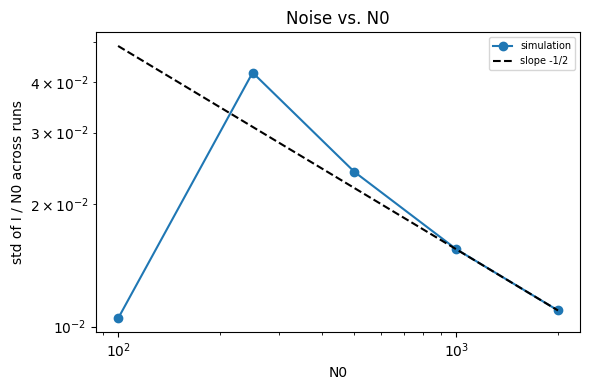

In [14]:
import matplotlib.patheffects as pe

values = [100, 250, 500, 1000, 2000]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
outline = [pe.Stroke(linewidth=4, foreground="white"), pe.Normal()]

t_max_long = 1000
t_burn = 300
n_runs_N = 40
t_grid_long = np.linspace(0, t_max_long, 1000)
after = t_grid_long >= t_burn
t_plot = t_grid_long[after]
dt = t_grid_long[1] - t_grid_long[0]

results = []
stds = []

for N0 in values:
    params = {**base, "N0": N0}
    I0 = max(1, round(0.01 * N0))
    start = [N0 - I0, I0, 0]
    runs = run_ensemble(start, params, t_max_long, n_runs_N, t_grid_long)
    I_frac = runs[:, after, 1] / N0
    n_extinct = (I_frac[:, -1] == 0).sum()
    results.append((N0, I_frac, n_extinct))

    stds.append(I_frac.std(axis=0, ddof=1).mean())

fig, ax = plt.subplots(figsize=(6, 4))
for (N0, I_frac, n_extinct), color in zip(results, colors):
    ax.plot(t_plot, I_frac.T, color=color, alpha=0.08, linewidth=0.8)
    ax.plot(t_plot, I_frac.mean(axis=0), color=color, linewidth=2.5,
            path_effects=outline,
            label=f"N0={N0} ({n_extinct} extinct)")
ax.set_xlabel("time")
ax.set_ylabel("I / N0")
ax.set_title("I / N0")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for (N0, I_frac, n_extinct), color in zip(results, colors):
    freqs, psd = power_spectrum(I_frac, dt)
    ax.semilogy(freqs[1:], psd[1:], color=color, label=f"N0={N0}")
ax.axvline(natural_frequency(base), color="k", linestyle="--",
           label="linearized")
ax.set_xlim(0, 0.05)
ax.set_xlabel("frequency (cycles per time unit)")
ax.set_ylabel("power of I / N0")
ax.set_title("Power spectrum")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

values_arr = np.array(values)
stds = np.array(stds)
reference = stds[-1] * np.sqrt(values_arr[-1] / values_arr)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(values_arr, stds, "o-", label="simulation")
ax.loglog(values_arr, reference, "k--", label="slope -1/2")
ax.set_xlabel("N0")
ax.set_ylabel("std of I / N0 across runs")
ax.set_title("Noise vs. N0")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()